# Logistic Regression Project: Diabetes Prediction (Pima Indians, Kaggle)
**Student:** _Arpita Lunkad  **Date:** 02/11/2026

**Objective:** Predict `Outcome` (0 = No diabetes, 1 = Diabetes) using median imputation + StandardScaler + balanced Logistic Regression.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)

## 1. Load the Kaggle CSV
Upload `diabetes.csv` (Pima Indians Diabetes Database) to the same folder / Colab files panel.

In [5]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Inspect the data

In [6]:
print(df.shape)
df.info()
display(df.describe().T)
print(df['Outcome'].value_counts())

(768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Outcome
0    500
1    268
Name: count, dtype: int64


In [7]:
# Zeros that are biologically impossible
zero_cols = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
print((df[zero_cols] == 0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


## 3. Replace invalid zeros with NaN

In [8]:
df[zero_cols] = df[zero_cols].replace(0, np.nan)
print(df.isna().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


## 4. Train-test split (fixed, stratified)

In [9]:
X = df.drop(columns='Outcome')
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(614, 8) (154, 8)


## 5. Pipeline: median imputation → scaling → balanced Logistic Regression

In [10]:
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

## 6. Evaluation

In [11]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame({
    'Metric': ['Accuracy','Precision','Recall','F1-score','ROC-AUC'],
    'Result': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
               recall_score(y_test, y_pred), f1_score(y_test, y_pred),
               roc_auc_score(y_test, y_prob)]
}).round(3)
display(metrics)
print(classification_report(y_test, y_pred))

,Metric,Result
0,Accuracy,0.734
1,Precision,0.603
2,Recall,0.704
3,F1-score,0.650
4,ROC-AUC,0.813


              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



TN=75  FP=25  FN=16  TP=38


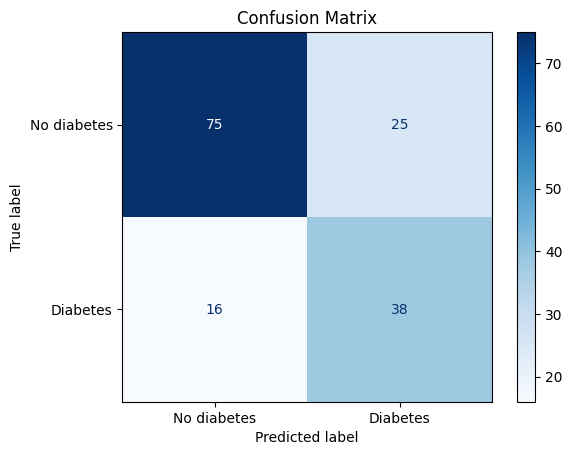

In [12]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
ConfusionMatrixDisplay(cm, display_labels=['No diabetes','Diabetes']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

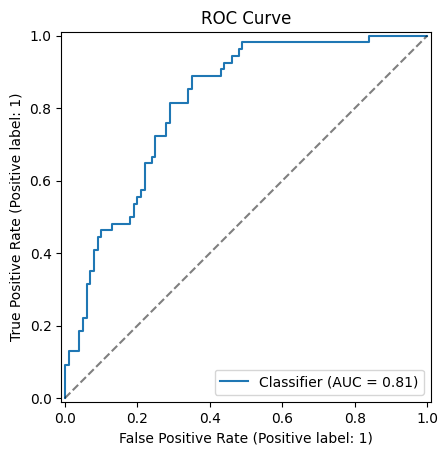

In [13]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.plot([0,1],[0,1],'k--', alpha=0.5)
plt.title('ROC Curve')
plt.show()

## 7. Interpret coefficients

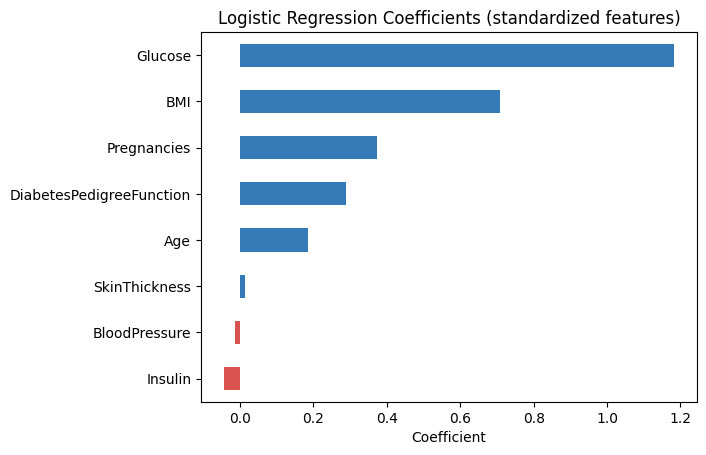

,0
Glucose,1.183483
BMI,0.709592
Pregnancies,0.372902
DiabetesPedigreeFunction,0.287734
Age,0.186434
SkinThickness,0.013980
BloodPressure,-0.014612
Insulin,-0.044609


In [14]:
coefs = pd.Series(model.named_steps['clf'].coef_[0], index=X.columns).sort_values()
coefs.plot(kind='barh', color=['#d9534f' if c < 0 else '#337ab7' for c in coefs])
plt.title('Logistic Regression Coefficients (standardized features)')
plt.xlabel('Coefficient')
plt.show()
coefs.sort_values(ascending=False)